In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


In [31]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### Data cleaning

In [32]:
print(df.duplicated().sum())
print(df["Transported"].isna().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["Transported"])
df.head()

0
0


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### Feature engineering

In [33]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
target = train["Transported"]

all_passengers = pd.concat(
    [train.drop(columns="Transported"), test],
    ignore_index=True
)

def add_features(df):
    df = df.copy()

    df["GroupId"] = df["PassengerId"].str.split("_").str[0]
    df["GroupSize"] = df.groupby("GroupId")["GroupId"].transform("size")
    df["IsAlone"] = (df["GroupSize"] == 1).astype(int)

    cabin = df["Cabin"].str.split("/", expand=True)
    df["Deck"] = cabin[0]
    df["CabinNumber"] = pd.to_numeric(cabin[1], errors="coerce")
    df["Side"] = cabin[2]

    spending = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
    df["TotalSpend"] = df[spending].sum(axis=1, min_count=1)
    df["MissingSpendValues"] = df[spending].isna().sum(axis=1)

    return df.drop(columns=["PassengerId", "GroupId", "Cabin", "Name"])

features = add_features(all_passengers)
X = features.iloc[:len(train)].copy()
y = target.copy()

### Model training

In [34]:
numeric_columns = [
    "Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck",
    "GroupSize", "IsAlone", "CabinNumber", "TotalSpend", "MissingSpendValues"
]
categorical_columns = [
    "HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side"
]
preprocessor = ColumnTransformer([
    ("numbers", SimpleImputer(strategy="median"), numeric_columns),
    ("categories", Pipeline([
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns)
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model.fit(X_train, y_train)
validation_predictions = model.predict(X_test)
print("Validation accuracy:", accuracy_score(y_test, validation_predictions))

Validation accuracy: 0.7918343875790684


### Prediction visualized

Test rows: 4277, predictions: 4277
  PassengerId   Age HomePlanet  PredictedTransported
0     0013_01  27.0      Earth                  True
1     0018_01  19.0      Earth                 False
2     0019_01  31.0     Europa                  True
3     0021_01  38.0     Europa                  True
4     0023_01  20.0      Earth                  True
5     0027_01  31.0      Earth                  True
6     0029_01  21.0     Europa                  True
7     0032_01  20.0     Europa                  True
8     0032_02  23.0     Europa                  True
9     0033_01  24.0      Earth                  True


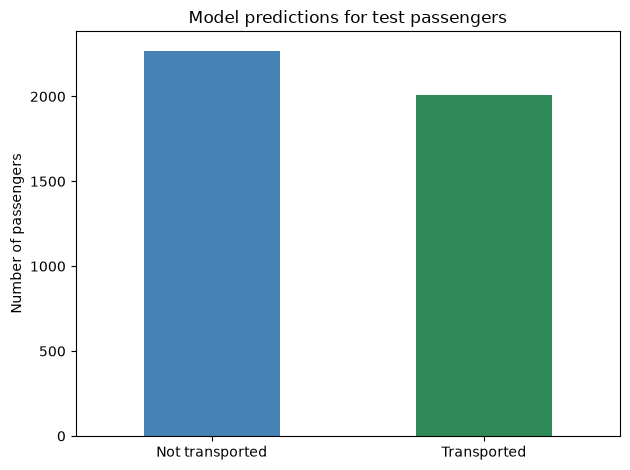

In [35]:
X_test = features.iloc[len(train):].copy()

model.fit(X, y)
test_predictions = model.predict(X_test)

print(f"Test rows: {len(test)}, predictions: {len(test_predictions)}")

results = test[["PassengerId", "Age", "HomePlanet"]].copy()
results["PredictedTransported"] = test_predictions

print(results.head(10))

counts = results["PredictedTransported"].value_counts().reindex(
    [False, True], fill_value=0
)
counts.index = ["Not transported", "Transported"]

counts.plot(kind="bar", color=["steelblue", "seagreen"])
plt.title("Model predictions for test passengers")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

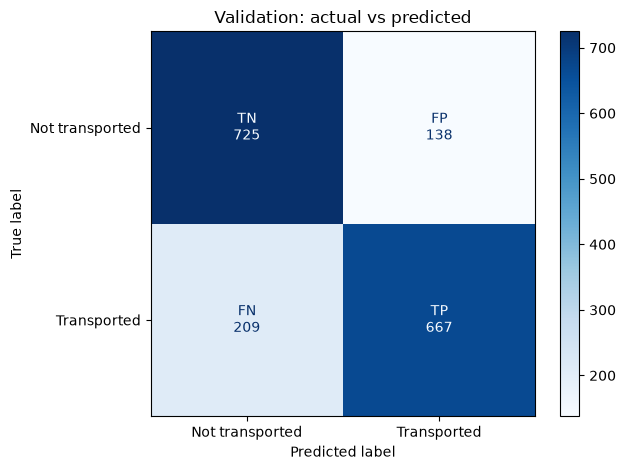

In [40]:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test,
    validation_predictions,
    labels=[False, True],
    display_labels=["Not transported", "Transported"],
    cmap="Blues"
)

# Rows are actual labels; columns are predicted labels.
cell_names = [["TN", "FP"], ["FN", "TP"]]
for row in range(2):
    for col in range(2):
        count = disp.confusion_matrix[row, col]
        disp.text_[row, col].set_text(f"{cell_names[row][col]}\n{count}")

plt.title("Validation: actual vs predicted")
plt.tight_layout()
plt.show()